In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:")
print(PROJECT_ROOT)

Project root:
c:\Users\asus\OneDrive\Desktop\siamese-network


In [2]:
NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"

CLASS_NAMES = ["normal", "irf", "orf"]

signals = {}

for class_name in CLASS_NAMES:
    path = NORMALIZED_DIR / f"{class_name}.csv"

    data = np.loadtxt(
        path,
        delimiter=",",
        dtype=np.float32
    )

    signals[class_name] = data

    print(
        f"{class_name.upper():6s}: "
        f"{data.shape}"
    )

NORMAL: (100, 100000)
IRF   : (100, 100000)
ORF   : (100, 100000)


In [4]:
from src.gaf import signal_to_gaf

IMAGE_SIZES = [224, 512, 1024]

# Select one representative signal from each class.
# We can later inspect more if necessary.

representative_signals = {
    class_name: signals[class_name][0]
    for class_name in CLASS_NAMES
}

resolution_examples = {}

for class_name, signal in representative_signals.items():

    resolution_examples[class_name] = {}

    for image_size in IMAGE_SIZES:

        gasf, gadf = signal_to_gaf(
            signal,
            image_size=image_size
        )

        resolution_examples[class_name][image_size] = {
            "gasf": gasf,
            "gadf": gadf
        }

        print(
            f"{class_name.upper():6s} | "
            f"{image_size:4d}x{image_size:<4d} | "
            f"GASF {gasf.shape} | "
            f"GADF {gadf.shape}"
        )

NORMAL |  224x224  | GASF (224, 224) | GADF (224, 224)
NORMAL |  512x512  | GASF (512, 512) | GADF (512, 512)
NORMAL | 1024x1024 | GASF (1024, 1024) | GADF (1024, 1024)
IRF    |  224x224  | GASF (224, 224) | GADF (224, 224)
IRF    |  512x512  | GASF (512, 512) | GADF (512, 512)
IRF    | 1024x1024 | GASF (1024, 1024) | GADF (1024, 1024)
ORF    |  224x224  | GASF (224, 224) | GADF (224, 224)
ORF    |  512x512  | GASF (512, 512) | GADF (512, 512)
ORF    | 1024x1024 | GASF (1024, 1024) | GADF (1024, 1024)


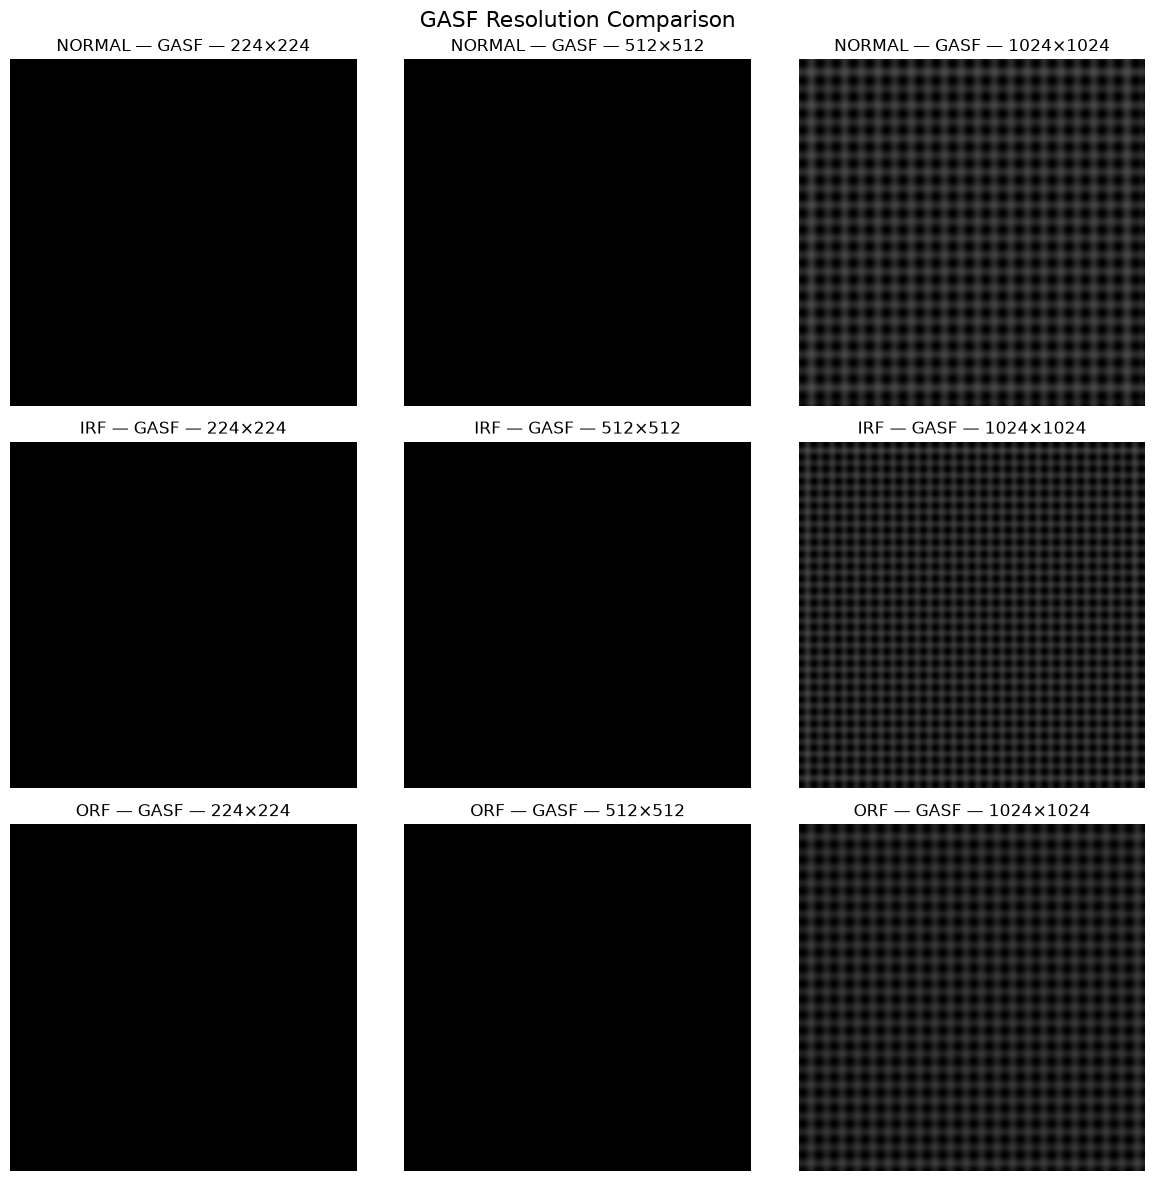

In [5]:
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

for row, class_name in enumerate(CLASS_NAMES):

    for col, image_size in enumerate(IMAGE_SIZES):

        image = resolution_examples[class_name][image_size]["gasf"]

        ax = axes[row, col]

        ax.imshow(
            image,
            cmap="gray",
            vmin=-1,
            vmax=1
        )

        ax.set_title(
            f"{class_name.upper()} — GASF — "
            f"{image_size}×{image_size}"
        )

        ax.axis("off")

fig.suptitle(
    "GASF Resolution Comparison",
    fontsize=16
)

fig.tight_layout()

plt.show()

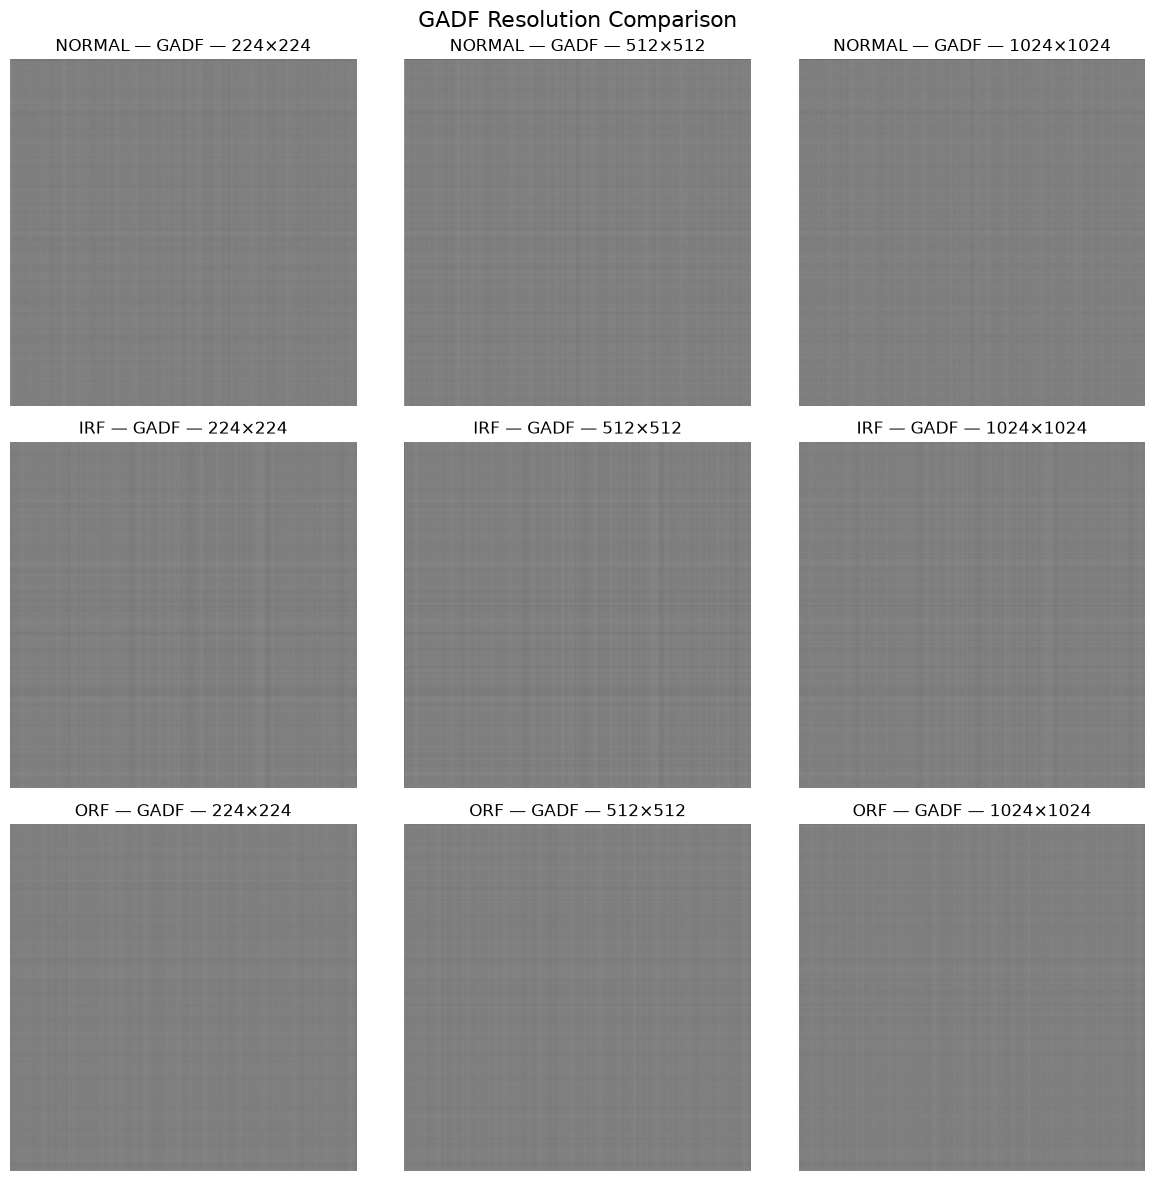

In [7]:
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

for row, class_name in enumerate(CLASS_NAMES):

    for col, image_size in enumerate(IMAGE_SIZES):

        image = resolution_examples[class_name][image_size]["gadf"]

        ax = axes[row, col]

        ax.imshow(
            image,
            cmap="gray",
            vmin=-1,
            vmax=1
        )

        ax.set_title(
            f"{class_name.upper()} — GADF — "
            f"{image_size}×{image_size}"
        )

        ax.axis("off")

fig.suptitle(
    "GADF Resolution Comparison",
    fontsize=16
)

fig.tight_layout()

plt.show()

In [8]:
FIGURES_DIR = PROJECT_ROOT / "datasets" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# GASF
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

for row, class_name in enumerate(CLASS_NAMES):
    for col, image_size in enumerate(IMAGE_SIZES):

        image = resolution_examples[class_name][image_size]["gasf"]

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=-1,
            vmax=1
        )

        axes[row, col].set_title(
            f"{class_name.upper()} — {image_size}×{image_size}"
        )

        axes[row, col].axis("off")

fig.suptitle(
    "GASF — Resolution Comparison",
    fontsize=16
)

fig.tight_layout()

gasf_comparison_path = (
    FIGURES_DIR / "gaf_resolution_gasf.png"
)

fig.savefig(
    gasf_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)


# GADF
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

for row, class_name in enumerate(CLASS_NAMES):
    for col, image_size in enumerate(IMAGE_SIZES):

        image = resolution_examples[class_name][image_size]["gadf"]

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=-1,
            vmax=1
        )

        axes[row, col].set_title(
            f"{class_name.upper()} — {image_size}×{image_size}"
        )

        axes[row, col].axis("off")

fig.suptitle(
    "GADF — Resolution Comparison",
    fontsize=16
)

fig.tight_layout()

gadf_comparison_path = (
    FIGURES_DIR / "gaf_resolution_gadf.png"
)

fig.savefig(
    gadf_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Saved:")
print(gasf_comparison_path)
print(gadf_comparison_path)

Saved:
c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\figures\gaf_resolution_gasf.png
c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\figures\gaf_resolution_gadf.png


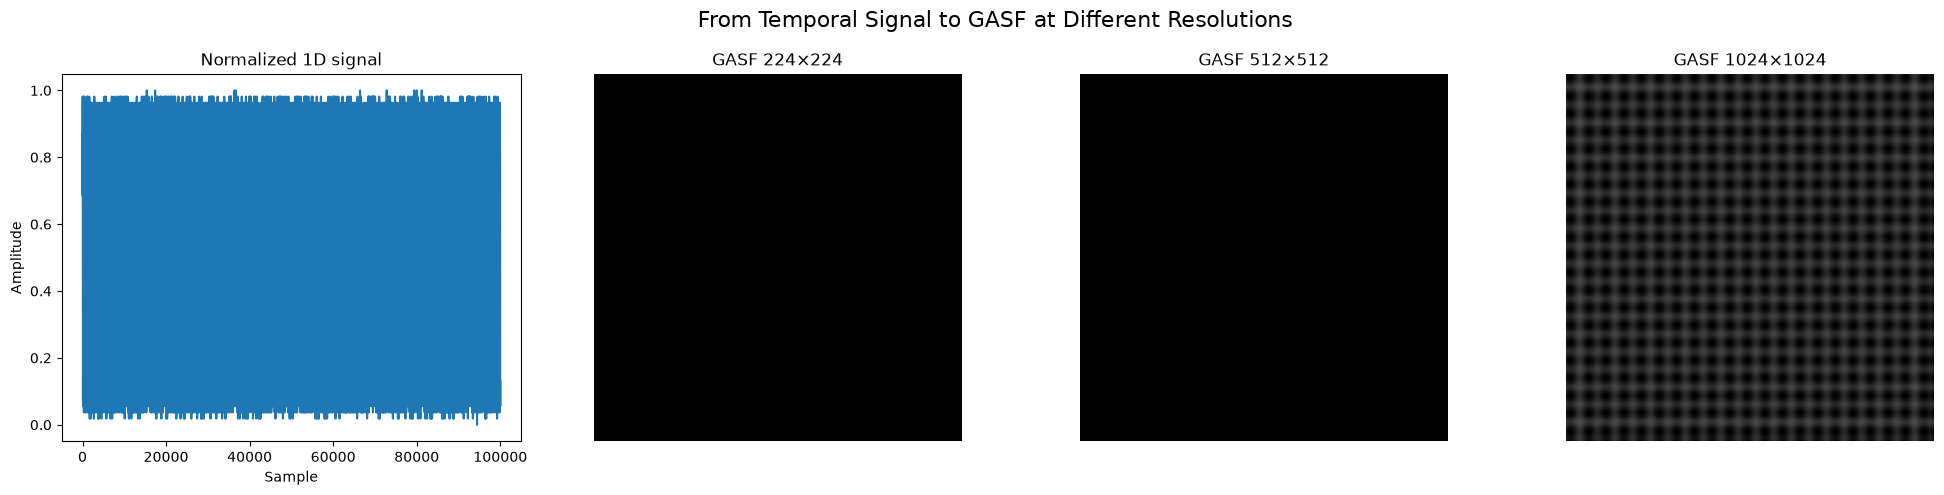

In [9]:
class_name = "normal"

signal = representative_signals[class_name]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# Original normalized signal
axes[0].plot(signal)
axes[0].set_title("Normalized 1D signal")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")

# GASF 224
axes[1].imshow(
    resolution_examples[class_name][224]["gasf"],
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[1].set_title("GASF 224×224")
axes[1].axis("off")

# GASF 512
axes[2].imshow(
    resolution_examples[class_name][512]["gasf"],
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[2].set_title("GASF 512×512")
axes[2].axis("off")

# GASF 1024
axes[3].imshow(
    resolution_examples[class_name][1024]["gasf"],
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[3].set_title("GASF 1024×1024")
axes[3].axis("off")

fig.suptitle(
    "From Temporal Signal to GASF at Different Resolutions",
    fontsize=16
)

fig.tight_layout()

plt.show()

In [10]:
# ============================================================
# Generate complete 512x512 GASF + GADF dataset
# ============================================================

from pathlib import Path
import numpy as np
from PIL import Image

from src.gaf import signal_to_gaf


IMAGE_SIZE = 512

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"
IMAGE_ROOT_512 = PROJECT_ROOT / "datasets" / "images_512"

CLASS_NAMES = ["normal", "irf", "orf"]


# ------------------------------------------------------------
# Create output directories
# ------------------------------------------------------------

for representation in ["gasf", "gadf"]:
    for class_name in CLASS_NAMES:
        path = (
            IMAGE_ROOT_512
            / representation
            / class_name
        )
        path.mkdir(
            parents=True,
            exist_ok=True
        )


# ------------------------------------------------------------
# Generate images
# ------------------------------------------------------------

for class_name in CLASS_NAMES:

    csv_path = (
        NORMALIZED_DIR
        / f"{class_name}.csv"
    )

    signals = np.loadtxt(
        csv_path,
        delimiter=",",
        dtype=np.float32
    )

    print(
        f"\nGenerating {class_name.upper()} "
        f"({len(signals)} signals)"
    )

    for index, signal in enumerate(signals):

        gasf, gadf = signal_to_gaf(
            signal,
            image_size=IMAGE_SIZE
        )

        # Convert [-1, 1] → [0, 255]
        gasf_uint8 = (
            ((gasf + 1.0) / 2.0) * 255.0
        ).clip(0, 255).astype(np.uint8)

        gadf_uint8 = (
            ((gadf + 1.0) / 2.0) * 255.0
        ).clip(0, 255).astype(np.uint8)

        gasf_path = (
            IMAGE_ROOT_512
            / "gasf"
            / class_name
            / f"{class_name}_{index:03d}.png"
        )

        gadf_path = (
            IMAGE_ROOT_512
            / "gadf"
            / class_name
            / f"{class_name}_{index:03d}.png"
        )

        Image.fromarray(
            gasf_uint8,
            mode="L"
        ).save(gasf_path)

        Image.fromarray(
            gadf_uint8,
            mode="L"
        ).save(gadf_path)

    print(
        f"Finished {class_name.upper()}"
    )

print("\n512x512 image generation complete.")
print("Root:", IMAGE_ROOT_512)


Generating NORMAL (100 signals)
Finished NORMAL

Generating IRF (100 signals)
Finished IRF

Generating ORF (100 signals)
Finished ORF

512x512 image generation complete.
Root: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\images_512


In [ ]:
# ============================================================
# Verify 512x512 image dataset
# ============================================================

from PIL import Image

for representation in ["gasf", "gadf"]:

    print(f"\n{representation.upper()}")

    for class_name in CLASS_NAMES:

        directory = (
            IMAGE_ROOT_512
            / representation
            / class_name
        )

        files = sorted(directory.glob("*.png"))

        print(
            f"{class_name:6s}: "
            f"{len(files)} images"
        )

        if len(files) > 0:

            with Image.open(files[0]) as image:
                print(
                    "        shape:",
                    image.size,
                    "mode:",
                    image.mode
                )


GASF
normal: 100 images
        shape: (512, 512) mode: L
irf   : 100 images
        shape: (512, 512) mode: L
orf   : 100 images
        shape: (512, 512) mode: L

GADF
normal: 100 images
        shape: (512, 512) mode: L
irf   : 100 images
        shape: (512, 512) mode: L
orf   : 100 images
        shape: (512, 512) mode: L


: 